# Week 8 — Model Evaluation with Molecular Properties

## Comparing classification models fairly

This notebook adapts the Week 8 evaluation lesson to `properties.csv`.

**Task:** classify each compound as having a Mannhold LogP at or below the dataset median (class 0), or above the median (class 1).

The median in this dataset is **2.45**. This creates two reasonably balanced groups. It is a teaching classification task: it predicts a LogP category, not biological activity.

We use molecular descriptors as inputs. We deliberately exclude identifiers, molecule names, the Mannhold LogP target itself, and `XLogP` (another LogP estimate) to avoid target leakage.

We will practise:
- why training performance is not enough;
- training, validation and test sets;
- accuracy, precision, recall, F1 and confusion matrices;
- stratified cross-validation;
- using pipelines to prevent preprocessing leakage.

**Before running:** put this notebook and `properties(1).csv` in the same folder, or update `DATA_PATH` below.

## 1. Set up the molecular-property data

The original notebook used simulated student-support data. Here we use molecular descriptors from the project dataset.

The target is made from `Mannhold LogP`:
- `0`: Mannhold LogP is less than or equal to 2.45
- `1`: Mannhold LogP is greater than 2.45

The model does not receive Mannhold LogP or XLogP as an input. Numeric descriptors are used instead. Some descriptor columns are stored as text in the CSV, so we convert them to numbers. Missing descriptor values will be filled with the median inside each pipeline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

RANDOM_STATE = 42
DATA_PATH = r"C:\COLLEGE\CSC1171\Week 1\week3-DataIntro\notebooks\properties.csv"  # Keep the CSV in the same folder as this notebook.

# Numeric molecular descriptors used as model inputs.
# XLogP is deliberately excluded because it is another LogP estimate.
feature_names = ['Molecular Weight', 'Topological Polar Surface Area', 'Hydrogen Bond Acceptors', 'Hydrogen Bond Donors', 'Rotatable Bonds Count', 'Aromatic Atoms Count', 'Aromatic Bonds Count', 'Bond Count', 'Largest Chain', 'Largest Pi Chain', 'SP3 Character', 'Formal Charge', 'Zagreb Index']

df = pd.read_csv(DATA_PATH)

# Convert selected descriptors to numeric values. Any unconvertible values
# become NaN and are imputed inside each model pipeline.
for col in feature_names:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without the target, then define a binary target:
# 0 = Mannhold LogP at or below the dataset median
# 1 = Mannhold LogP above the dataset median
df = df.dropna(subset=["Mannhold LogP"]).copy()
logp_cutoff = df["Mannhold LogP"].median()
y = (df["Mannhold LogP"] > logp_cutoff).astype(int)
X = df[feature_names].copy()

print("Dataset rows:", len(df))
print("Number of input features:", len(feature_names))
print(f"Mannhold LogP median cutoff: {logp_cutoff:.2f}")
print("Class counts (0 = lower/equal, 1 = higher):")
print(y.value_counts().sort_index())
display(X.head())


Dataset rows: 15166
Number of input features: 13
Mannhold LogP median cutoff: 2.45
Class counts (0 = lower/equal, 1 = higher):
Mannhold LogP
0    7874
1    7292
Name: count, dtype: int64


,Molecular Weight,Topological Polar Surface Area,Hydrogen Bond Acceptors,Hydrogen Bond Donors,Rotatable Bonds Count,Aromatic Atoms Count,Aromatic Bonds Count,Bond Count,Largest Chain,Largest Pi Chain,SP3 Character,Formal Charge,Zagreb Index
0,17.026549,0.00,1,1,0,0,0,0,0,0,0.000000,0,0
1,180.042259,63.60,3,1,5,6,6,13,3,12,0.047619,0,60
2,26.015650,0.00,0,0,0,0,0,1,2,2,0.000000,0,2
3,506.995745,308.56,17,7,15,9,10,33,8,13,0.106383,0,170
4,349.109627,138.03,7,3,8,6,6,26,4,6,0.162791,0,132


## 2. Inspect the class balance

It is important to know how many compounds belong to each class. Accuracy can be misleading when one class is much more common than the other.

The class balance here should be close to 50/50 because the median is used as the cutoff. Ties at exactly the median are assigned to class 0.

In [2]:
# Inspect the class balance as proportions.
y.value_counts(normalize=True).sort_index()

Mannhold LogP
0    0.519188
1    0.480812
Name: proportion, dtype: float64

## 3. Split the data before fitting a model

We use 60% for training, 20% for validation and 20% for testing.

- **Training:** fit model parameters.
- **Validation:** compare candidate models.
- **Test:** final independent evaluation, used only after choosing a model.

`stratify=y` keeps the class proportions similar in each split.

In [3]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Train:      {len(X_train):5d} rows ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_valid):5d} rows ({len(X_valid)/len(X):.0%})")
print(f"Test:       {len(X_test):5d} rows ({len(X_test)/len(X):.0%})")

Train:       9099 rows (60%)
Validation:  3033 rows (20%)
Test:        3034 rows (20%)


## 4. Compare classifiers on the validation set

We compare Logistic Regression, K-Nearest Neighbours (KNN) and a Decision Tree.

Logistic Regression and KNN are sensitive to feature scales, so their pipelines impute missing values, standardise the descriptors, and then fit the classifier. The Decision Tree uses imputation but does not need scaling.

Putting preprocessing inside a pipeline means the imputer and scaler are fitted only on the training portion of each split.

In [4]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "KNN (k=15)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=15))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
    ])
}

validation_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0)
    })

validation_results = (pd.DataFrame(validation_rows)
                      .set_index("Model")
                      .sort_values("F1", ascending=False))
display(validation_results.round(3))

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.935,0.935,0.930,0.932
KNN (k=15),0.922,0.901,0.940,0.920
Decision Tree,0.916,0.890,0.942,0.915


### Which metric should we use?

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** among compounds predicted as high LogP, the proportion that truly are high LogP.
- **Recall:** among truly high-LogP compounds, the proportion identified by the model.
- **F1:** balances precision and recall.

Here class 1 means higher Mannhold LogP. The most useful metric depends on the purpose of the classification. We report all four rather than relying on accuracy alone.

## 5. Read a confusion matrix

Rows are the actual classes and columns are the predicted classes.

For this task:
- **True positive:** a high-LogP compound correctly predicted as high.
- **True negative:** a lower/equal-LogP compound correctly predicted as lower/equal.
- **False positive:** a lower/equal-LogP compound incorrectly predicted as high.
- **False negative:** a high-LogP compound incorrectly predicted as lower/equal.

Selected using validation F1: Logistic Regression
Confusion matrix (actual rows, predicted columns):
[[1480   95]
 [ 102 1356]]


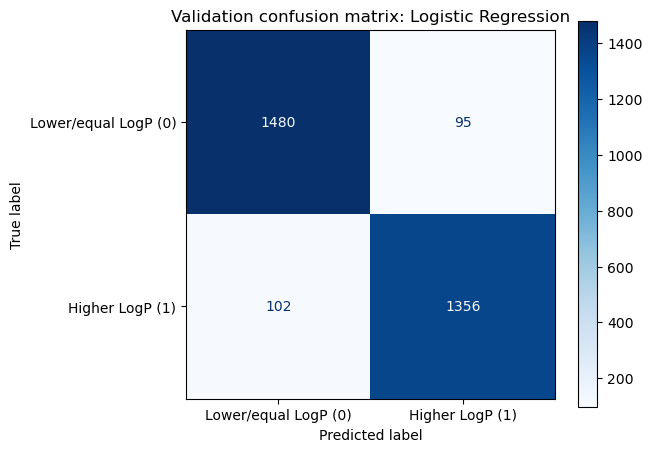

In [5]:
# Choose the model with the highest validation F1 score.
best_name = validation_results.index[0]
best_model = models[best_name]
valid_pred = best_model.predict(X_valid)

print("Selected using validation F1:", best_name)
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_valid, valid_pred, labels=[0, 1]))

ConfusionMatrixDisplay.from_predictions(
    y_valid, valid_pred, labels=[0, 1],
    display_labels=["Lower/equal LogP (0)", "Higher LogP (1)"],
    cmap="Blues"
)
plt.title(f"Validation confusion matrix: {best_name}")
plt.tight_layout()
plt.show()

**Think about it:** If the goal were to identify as many higher-LogP compounds as possible, would recall or precision be the more relevant starting point? What trade-off might follow?

## 6. Cross-validation for a more stable comparison

A single validation split can depend on which rows happened to be held out. In 5-fold stratified cross-validation, the training data are split into five folds. Each fold is used for validation once.

We run cross-validation on the training portion only. The test set remains untouched. We report the mean and standard deviation of the scores across folds.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"],
        return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "Accuracy mean": scores["test_accuracy"].mean(),
        "Accuracy SD": scores["test_accuracy"].std(),
        "Precision mean": scores["test_precision"].mean(),
        "Recall mean": scores["test_recall"].mean(),
        "F1 mean": scores["test_f1"].mean(),
        "F1 SD": scores["test_f1"].std()
    })

cv_results = (pd.DataFrame(cv_rows)
              .set_index("Model")
              .sort_values("F1 mean", ascending=False))
display(cv_results.round(3))

,Accuracy mean,Accuracy SD,Precision mean,Recall mean,F1 mean,F1 SD
Model,,,,,,
Logistic Regression,0.939,0.003,0.935,0.937,0.936,0.003
Decision Tree,0.921,0.007,0.899,0.941,0.920,0.008
KNN (k=15),0.919,0.003,0.892,0.946,0.918,0.003


## 7. Data leakage and pipelines

Data leakage happens when information from the validation/test data, or information unavailable at prediction time, influences model fitting.

For example, fitting a scaler on the entire dataset before splitting allows information from held-out rows to influence preprocessing. The safe approach is to put imputation and scaling inside a pipeline. Cross-validation then refits those steps separately within each fold.

In [7]:
# Correct pattern: imputation and scaling are inside the pipeline.
safe_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

safe_scores = cross_validate(
    safe_model, X_train, y_train, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)
print("Mean CV F1 with pipeline:", round(safe_scores["test_f1"].mean(), 3))

Mean CV F1 with pipeline: 0.936


## 8. Final evaluation: use the test set once

We select the model using the validation results, then refit the same model settings on the combined training and validation data. Finally, we evaluate it on the test set.

Do not keep changing the model based on the test results. If you do, the test set becomes another validation set.

Final selected model: Logistic Regression
                  precision    recall  f1-score   support

Lower/equal LogP       0.95      0.92      0.94      1575
     Higher LogP       0.92      0.95      0.94      1459

        accuracy                           0.94      3034
       macro avg       0.94      0.94      0.94      3034
    weighted avg       0.94      0.94      0.94      3034



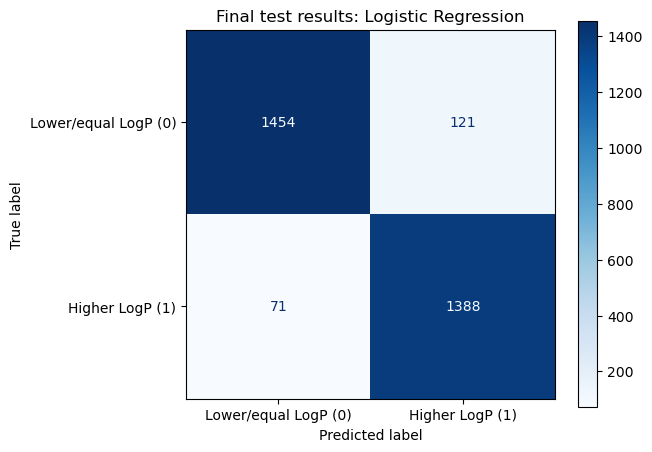

In [8]:
X_trainval = pd.concat([X_train, X_valid])
y_trainval = pd.concat([y_train, y_valid])

# Re-create the selected model with the same settings, then fit on train + validation.
final_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "KNN (k=15)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=15))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
    ])
}
final_model = final_models[best_name]
final_model.fit(X_trainval, y_trainval)
test_pred = final_model.predict(X_test)

print("Final selected model:", best_name)
print(classification_report(
    y_test, test_pred,
    target_names=["Lower/equal LogP", "Higher LogP"],
    zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["Lower/equal LogP (0)", "Higher LogP (1)"],
    cmap="Blues"
)
plt.title(f"Final test results: {best_name}")
plt.tight_layout()
plt.show()

## 9. Questions to discuss

1. Why is training accuracy not a reliable estimate of performance on new compounds?
2. When could accuracy be misleading?
3. What is the difference between precision and recall in this LogP classification task?
4. Why should model selection not be based on the test set?
5. How does a pipeline help prevent data leakage?

### Key message

**Choose and tune using training data plus validation/cross-validation. Keep the test set for the final estimate. Use metrics that match the purpose of the classification.**

**Project limitation:** this notebook predicts a high/low LogP category. The dataset does not contain bioactivity labels, so these results do not demonstrate bioactivity prediction.